# Mathematical Modelling for District-Level Drought Early Warning in Tanzania
### Reproducible research notebook | TMA Problem 6 | MATH4SDG 2026

**Study period:** 1981–2025  
**Case-study locations:** Longido, Monduli and Simanjiro, northern Tanzania  
**Forecast horizons:** 1, 2 and 3 months

**Research problem.** Can district-level drought conditions and vegetation stress be anticipated one to three months ahead, with skill beyond simple historical baselines?

**Objectives**
1. Reconstruct historical SPI-3 and quality-screened SPEI-3 drought conditions.
2. Assess associations between each index and independently observed vegetation stress.
3. Document the 2020–2022 northern Tanzania drought and TMA warnings.
4. Fit and evaluate mathematical forecasting models against historical benchmarks.
5. Interpret model skill, uncertainty and limitations in the context of an early-warning application.

This notebook reads the same datasets and result files used by the portable Python engine. It **recomputes selected formulas, independent checks and performance statistics**, and permits a full historical workflow rerun via the optional execution cell. All reported forecasts are **retrospective hindcasts**, not live TMA warnings.

## 1. Project setup and execution

Open `notebooks/TMA_P06_Complete_Research.ipynb` in JupyterLab **after extracting the entire project ZIP**. Run **Kernel → Restart Kernel and Run All Cells**. The notebook finds the project root automatically whether Jupyter starts in the project folder or inside `notebooks/`.

To regenerate the full SPI/SPEI, vegetation, case-study and model-fitting outputs from source scripts, change `RECOMPUTE_FULL_ENGINE` to `True`. It is `False` by default so that the notebook can be reviewed rapidly using the previously executed verified results. The full workflow may take substantially longer and will overwrite outputs under `outputs/`.

In [1]:
from pathlib import Path
import os, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import gamma, fisk, norm, spearmanr
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix
import joblib

RECOMPUTE_FULL_ENGINE = False

ROOT = next((p for start in [Path.cwd()] for p in [start, *start.parents] if (p/'run_project.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Project root not found. Extract the full ZIP and open Jupyter inside the project.')
print('Project root:', ROOT)
print('Python version:', sys.version.split()[0])
print('Research dataset:', (ROOT/'data/standardized/district_month_master.csv').is_file())
if RECOMPUTE_FULL_ENGINE:
    subprocess.run([sys.executable, str(ROOT/'run_project.py'), '--mode', 'all'],cwd=ROOT,check=True)

Project root: /mnt/data/TMA_P06_PHASE4_JUPYTER_RESEARCH
Python version: 3.13.5
Research dataset: True


## 2. Data sources and data quality

| Input | Actual source / coverage | Unit or scope |
|---|---|---|
| Monthly precipitation | CHIRPS v3, 150 districts, Jan 1981–Dec 2025 | mm/month; satellite–gauge gridded estimates |
| Potential evaporation | Land-screened **atmospheric ERA5**, partial district coverage | mm/month; **not native ERA5-Land** |
| NDVI vegetation greenness | WFP/MODIS, 76 districts in the supplied extract | unitless; whole-district vegetation, **not measured crop loss** |
| District geography | NBS 2022 district boundaries | fixed geography across historical years |
| Historical drought impacts | Dated TMA bulletins and limited disaster/livestock reports | case evidence, not complete district-month loss outcomes |

Missing values represent **missing observations**, never “no drought” or “no impact.” A research-period quality audit checks keys, units, three-month totals and statistical fit diagnostics.

In [2]:
master = pd.read_csv(ROOT/'data/standardized/district_month_master.csv', parse_dates=['month'], dtype={'district_code':str})
districts = pd.read_csv(ROOT/'data/standardized/district_reference.csv', dtype={'district_code':str})
assert len(master) == 81_000
assert master.district_code.nunique() == 150
assert not master.duplicated(['district_code','month']).any()
assert master.chirps3_rain_mm.notna().all() and master.chirps3_rain_mm.ge(0).all()
assert master.month.min() == pd.Timestamp('1981-01-01')
assert master.month.max() == pd.Timestamp('2025-12-01')

summ = pd.DataFrame([
    {'Variable':'CHIRPS monthly rainfall', 'Nonmissing district-months':master.chirps3_rain_mm.notna().sum(), 'Districts':master.loc[master.chirps3_rain_mm.notna(),'district_code'].nunique()},
    {'Variable':'Land-screened ERA5 potential evaporation', 'Nonmissing district-months':master.era5_pet_land_mm.notna().sum(), 'Districts':master.loc[master.era5_pet_land_mm.notna(),'district_code'].nunique()},
    {'Variable':'SPI-3, accepted fit', 'Nonmissing district-months':master.spi3_verified.notna().sum(), 'Districts':master.loc[master.spi3_verified.notna(),'district_code'].nunique()},
    {'Variable':'SPEI-3, accepted strict fit', 'Nonmissing district-months':master.spei3_loglogistic_verified.notna().sum(), 'Districts':master.loc[master.spei3_loglogistic_verified.notna(),'district_code'].nunique()},
    {'Variable':'NDVI anomaly', 'Nonmissing district-months':master.ndvi_z.notna().sum(), 'Districts':master.loc[master.ndvi_z.notna(),'district_code'].nunique()},
])
display(summ)

,Variable,Nonmissing district-months,Districts
0,CHIRPS monthly rainfall,81000,150
1,Land-screened ERA5 potential evaporation,73980,137
2,"SPI-3, accepted fit",74850,150
3,"SPEI-3, accepted strict fit",38952,123
4,NDVI anomaly,21432,76


In [3]:
# Independent verification of a three-month rainfall rolling sum.
example = master.loc[master.district.eq('Simanjiro'), ['month','chirps3_rain_mm','rain_3month_mm']].sort_values('month').copy()
example['calculated_3month_mm'] = example.chirps3_rain_mm.rolling(3,min_periods=3).sum()
mask = example.rain_3month_mm.notna()
max_abs_difference = np.max(np.abs(example.loc[mask,'calculated_3month_mm']-example.loc[mask,'rain_3month_mm']))
print('Maximum rainfall aggregation difference (mm):',round(float(max_abs_difference),6))
assert max_abs_difference < 0.001

Maximum rainfall aggregation difference (mm): 1e-05


## 3. Mathematical drought indices: SPI-3 and SPEI-3

**SPI-3** (*Standardized Precipitation Index, 3-month accumulation*) quantifies how unusual three-month rainfall is compared with the historical distribution for the **same district and calendar month**. For rainfall accumulation $R_{3,t}$, a fitted gamma distribution and a probability adjustment for zero rainfall yield

$$F_R(r)=q+(1-q)G_{\alpha,\beta}(r), \qquad SPI_{3,t}=\Phi^{-1}[F_R(R_{3,t})],$$

where $q$ is the reference fraction of zero-rainfall accumulations, $G$ is the gamma cumulative distribution function and $\Phi^{-1}$ is the standard-normal quantile function. The project fits separate distributions to each district–calendar-month during **1990–2019** and rejects poor fits.

**SPEI-3** (*Standardized Precipitation Evapotranspiration Index*) first estimates the climatic water balance $D_t=P_t-PET_t$. Its three-month accumulation $D_{3,t}$ is transformed via a fitted **three-parameter log-logistic** cumulative distribution $L$:

$$SPEI_{3,t}=\Phi^{-1}[L(D_{3,t})].$$

Both indices are **unitless standard-normal scores**. Moderate drought starts at an index $\leq -1$, severe drought at $\leq-1.5$, and extreme drought at $\leq -2$. These **measure observed conditions**; they are not issued future forecasts. The alternative `water_balance_score3_sensitivity` is a different standardized water-balance indicator and must **not** be called standard SPEI-3.

In [4]:
indices = pd.read_csv(ROOT/'outputs/historical/stage2_monthly_indices_quality_flagged.csv',dtype={'district_id':str},parse_dates=['month'])
fit = pd.read_csv(ROOT/'outputs/historical/stage2_distribution_fit_diagnostics.csv',dtype={'district_id':str})
assert len(indices)==81_000
assert indices.spi3_verified.notna().sum()==74_850
assert indices.spei3_loglogistic_verified.notna().sum()==38_952
# Recalculate an accepted SPI-3 score directly from the 1990-2019 gamma fit.
rows = fit.loc[fit.spi_fit_status.str.startswith('ACCEPTED',na=False), ['district_id','calendar_month']]
chosen = None
for rec in rows.itertuples(index=False):
    g = indices.loc[(indices.district_id == rec.district_id) & (indices.month.dt.month == rec.calendar_month)]
    t = g.loc[g.month.dt.year.eq(2021) & g.spi3_verified.notna()]
    if not t.empty:
        chosen = (rec.district_id,rec.calendar_month,g,t.iloc[0]);break
assert chosen is not None
name_id,month_id,series,record = chosen
ref = series.loc[series.month.dt.year.between(1990,2019),'rain3_independent_mm'].dropna().to_numpy()
positive = ref[ref>0]
shape, _, scale = gamma.fit(positive, floc=0)
q = np.mean(ref<=0)
r = float(record.rain3_independent_mm)
p = q*0.5 if r<=0 else q+(1-q)*gamma.cdf(r,shape,loc=0,scale=scale)
z_recomputed = float(norm.ppf(np.clip(p,1e-5,1-1e-5)))
print(f'SPI-3 example, district ID {name_id}, {record.month:%b %Y}: recomputed={z_recomputed:.6f}; stored={record.spi3_verified:.6f}')
assert abs(z_recomputed-record.spi3_verified)<1e-4

SPI-3 example, district ID 0101, Jan 2021: recomputed=0.777070; stored=0.777070


In [5]:
# Cross-check one strict SPEI-3 fit using the saved, screened log-logistic parameters.
accepted = fit.loc[(fit.spei_fit_status=='ACCEPTED_LOGLOGISTIC') & fit.spei_shape.notna()]
choice = None
for frow in accepted.itertuples(index=False):
    observed = indices[(indices.district_id == frow.district_id) & (indices.month.dt.month == frow.calendar_month) & indices.spei3_loglogistic_verified.notna()]
    if not observed.empty:
        choice=(frow,observed.iloc[-1]);break
assert choice is not None
frow,obs = choice
water_balance=float(obs.balance3_independent_mm)
fitted_p=fisk.cdf(water_balance,float(frow.spei_shape),loc=float(frow.spei_location),scale=float(frow.spei_scale))
computed_spei=norm.ppf(np.clip(fitted_p,1e-5,1-1e-5))
print(f'Accepted SPEI-3 example: recomputed={computed_spei:.6f}; stored={obs.spei3_loglogistic_verified:.6f}')
assert abs(computed_spei-obs.spei3_loglogistic_verified)<1e-4
print('Strict SPEI-3 accepted fraction:',round(indices.spei3_loglogistic_verified.notna().mean()*100,1),'%')

Accepted SPEI-3 example: recomputed=0.556458; stored=0.556458
Strict SPEI-3 accepted fraction: 48.1 %


## 4. Historical drought distribution, 1981–2025

For each district, a severe drought month is one with $SPI_{3,t}\leq-1.5$ (or the corresponding quality-approved SPEI score). A **drought episode** is a continuous run of qualifying months; adjacent severe months within an episode are not counted as independent drought events.

District comparisons must control for missing fitted months. The following ranking includes only districts meeting the research project's complete-calendar-month coverage criteria. Do not interpret SPI frequencies as crop-loss rankings.

,district,region,severe_or_worse_months,severe_percent_available,severe_drought_episodes
315,Ilemela,Mwanza,39,7.25,22
324,Serengeti,Mara,36,6.69,25
162,Tandahimba,Mtwara,36,6.69,24
402,Chato,Geita,36,6.69,25
300,Ukerewe,Mwanza,35,6.51,19
303,Magu,Mwanza,35,6.51,22
390,Geita,Geita,34,6.32,22
306,Nyamagana,Mwanza,34,6.32,19
312,Sengerema,Mwanza,33,6.13,23
153,Mtwara,Mtwara,33,6.13,21


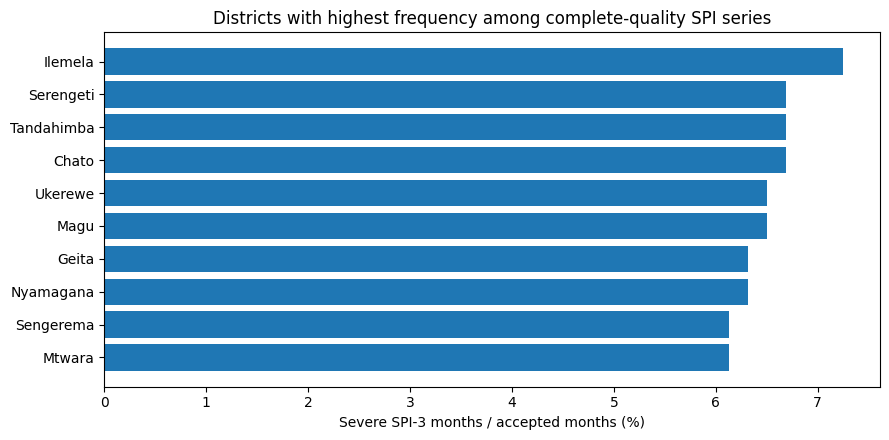

In [6]:
rank = pd.read_csv(ROOT/'outputs/historical/stage2_district_drought_frequency_rankings.csv')
r = rank[(rank.index_name=='SPI-3 verified') & (rank.complete_for_ranking==True)].sort_values('severe_percent_available',ascending=False)
display(r[['district','region','severe_or_worse_months','severe_percent_available','severe_drought_episodes']].head(10).round(2))
fig,ax=plt.subplots(figsize=(9,4.5))
top=r.head(10).iloc[::-1]
ax.barh(top.district,top.severe_percent_available)
ax.set_xlabel('Severe SPI-3 months / accepted months (%)')
ax.set_title('Districts with highest frequency among complete-quality SPI series')
fig.tight_layout();plt.show()

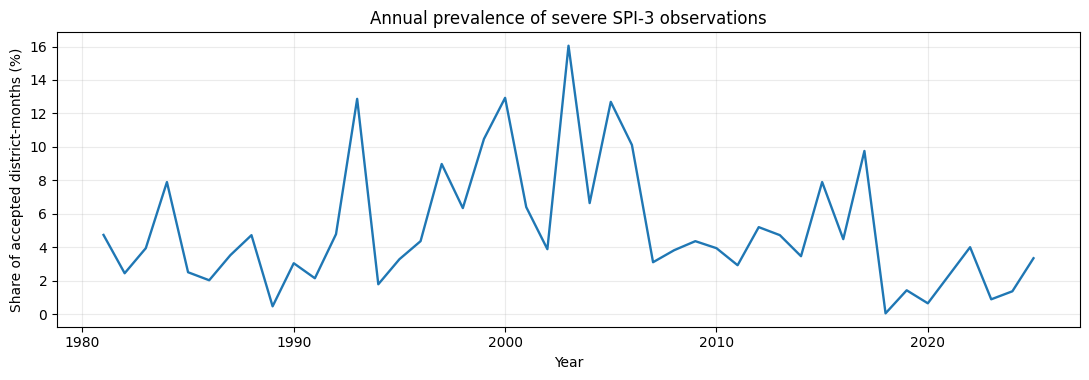

Largest annual severe-month share: 2003 — 16.05 %


In [7]:
annual = pd.read_csv(ROOT/'outputs/historical/stage2_annual_national_severe_months.csv')
a = annual[annual.index_name.eq('SPI-3 verified')].copy()
fig,ax=plt.subplots(figsize=(11,3.9))
ax.plot(a.year,a.severe_percent_valid,linewidth=1.7)
ax.set(xlabel='Year',ylabel='Share of accepted district-months (%)',title='Annual prevalence of severe SPI-3 observations')
ax.grid(alpha=.25);fig.tight_layout();plt.show()
print('Largest annual severe-month share:',int(a.loc[a.severe_percent_valid.idxmax(),'year']), '—',round(float(a.severe_percent_valid.max()),2),'%')

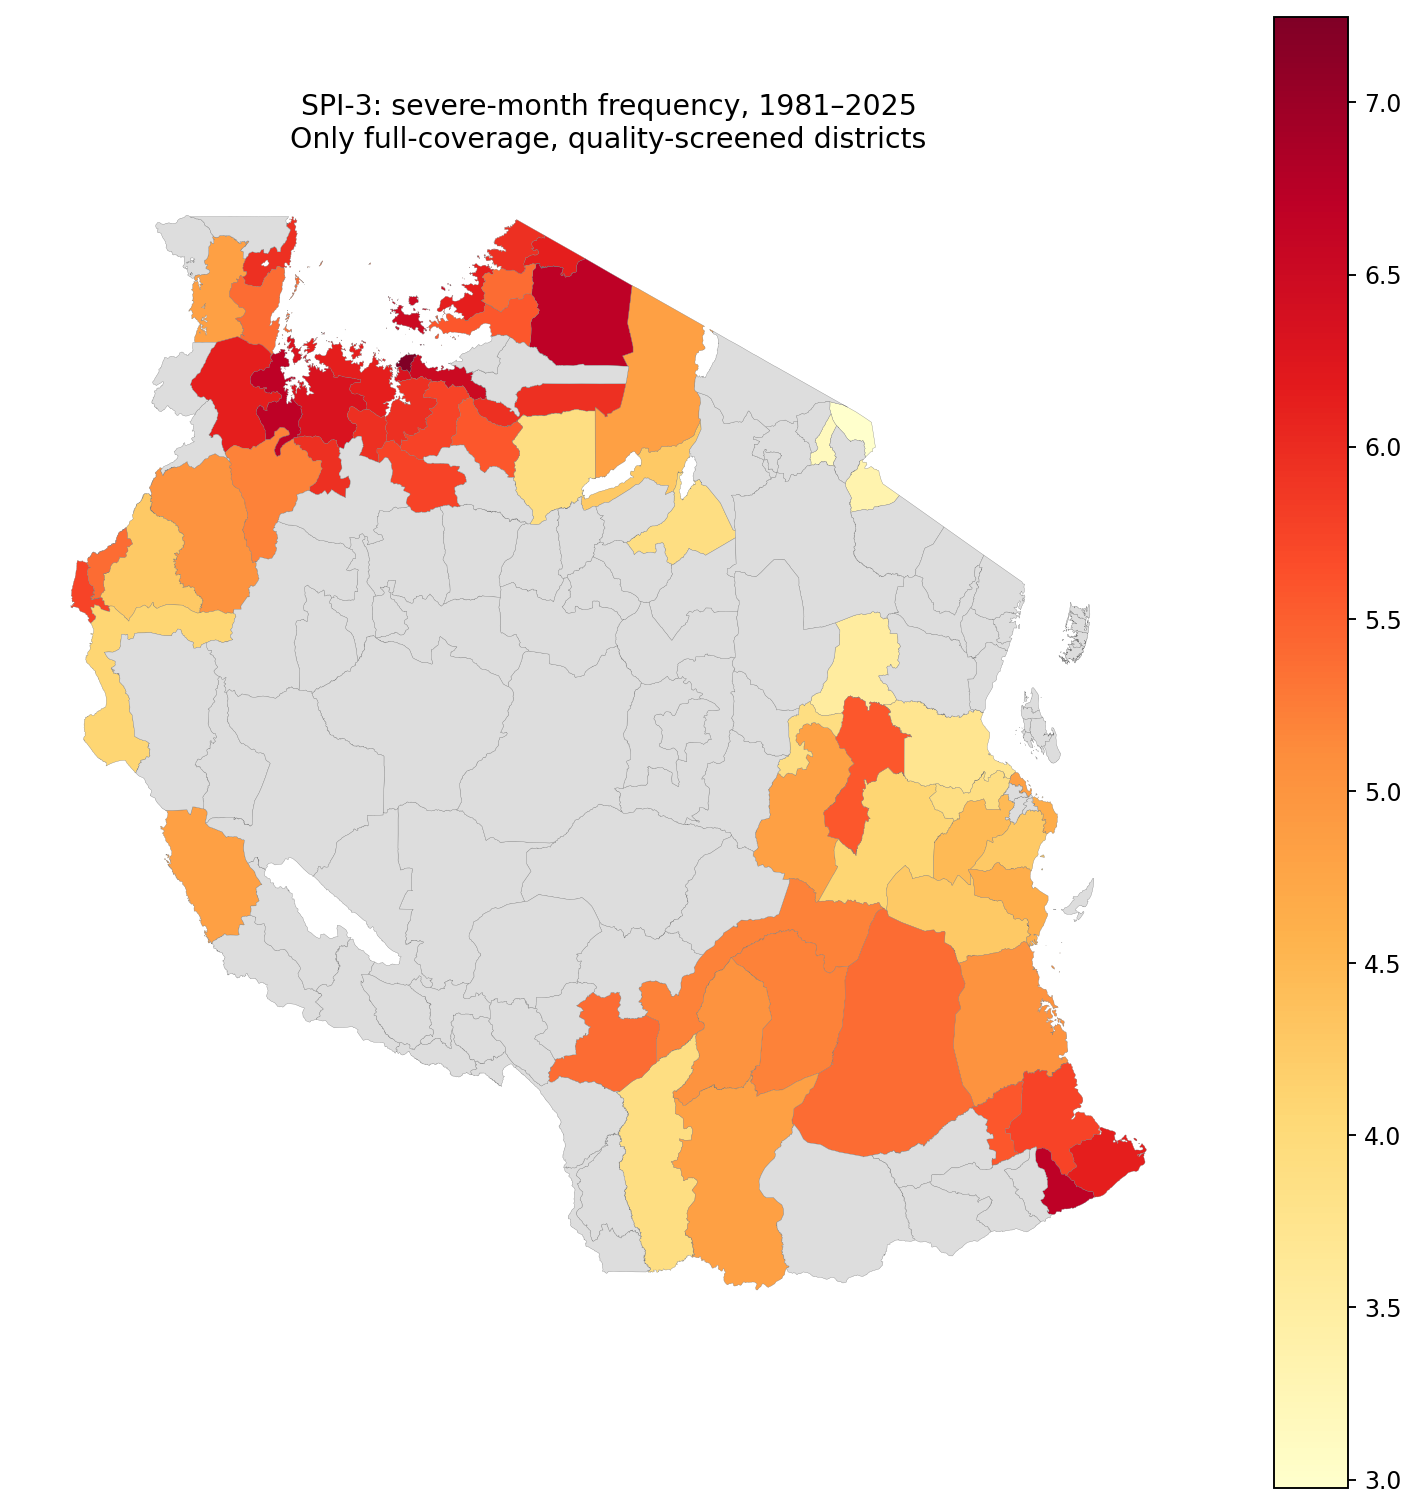

In [8]:
# Saved geospatial map comes from the verified Python engine (2022 fixed boundaries).
from IPython.display import Image
im = ROOT/'outputs/historical/stage2_spi3_quality_screened_frequency_map.png'
display(Image(filename=str(im),width=780))

## 5. Vegetation-stress validation: What do the indices represent?

NDVI measures satellite-observed vegetation greenness:

$$NDVI=\frac{NIR-Red}{NIR+Red}.$$

The **NDVI z-score** compares greenness with the historical mean and standard deviation for the same district and calendar month (2003–2019):

$$Z_{NDVI}=\frac{NDVI-\mu_{m,d}}{\sigma_{m,d}}.$$

A vegetation-stress month is defined here by $Z_{NDVI}\leq-1$. This definition is **not an observation of crop loss or livestock mortality**. The comparison aligns each observed drought index with NDVI in the same month and at 1-, 2-, or 3-month observational lags.

**Spearman's rank correlation** summarizes whether lower index values tend to coincide with lower NDVI. **ROC-AUC**, computed from `-SPI` or `-SPEI`, measures how well the index ranks observed stress versus non-stress cases. Higher AUC is better; these are **associations**, not forecast accuracy.

In [9]:
ndvi = pd.read_csv(ROOT/'outputs/impact_validation/stage3_ndvi_district_month_anomalies.csv',dtype={'district_id':str},parse_dates=['month'])
ndvi_row=ndvi.loc[(ndvi.ndvi_z.notna()) & (ndvi.ndvi_reference_sd>0)].iloc[0]
manual_ndvi_z=(ndvi_row.ndvi_monthly-ndvi_row.ndvi_reference_mean)/ndvi_row.ndvi_reference_sd
print('NDVI anomaly direct recomputation:',round(float(manual_ndvi_z),6),'stored:',round(float(ndvi_row.ndvi_z),6))
assert abs(manual_ndvi_z-ndvi_row.ndvi_z) < 1e-4

q=indices.merge(ndvi[['district_id','month','ndvi_z','vegetation_stress']],on=['district_id','month'],how='inner',validate='one_to_one')
q=q[q.month.dt.year.between(2020,2022)]
paired=q.dropna(subset=['spi3_verified','spei3_loglogistic_verified','ndvi_z']).copy()
assert len(paired)==1317 and paired.district_id.nunique()==69
rows=[]
for label,col in [('SPI-3','spi3_verified'),('SPEI-3 strict','spei3_loglogistic_verified')]:
    rows.append({'Index':label,'Matched months':len(paired),
       'Spearman rho':spearmanr(paired[col],paired.ndvi_z).statistic,
       'Stress AUC':roc_auc_score(paired.vegetation_stress.astype(int),-paired[col])})
res=pd.DataFrame(rows)
display(res.round(4))
ref = pd.read_csv(ROOT/'outputs/impact_validation/stage3_index_vegetation_metrics.csv')
ref=ref[(ref.period=='case_2020_2022')&(ref.lead_months==0)&(ref.cohort=='paired_SPI_SPEI')]
for lab,indexlab in [('SPI-3','SPI-3'),('SPEI-3 strict','SPEI-3 strict')]:
    assert abs(res.loc[res.Index==lab,'Stress AUC'].iloc[0]-ref.loc[ref['index']==indexlab,'roc_auc_vegetation_stress'].iloc[0])<2e-5

NDVI anomaly direct recomputation: 1.080304 stored: 1.080303


,Index,Matched months,Spearman rho,Stress AUC
0,SPI-3,1317,0.4754,0.8297
1,SPEI-3 strict,1317,0.5544,0.8523


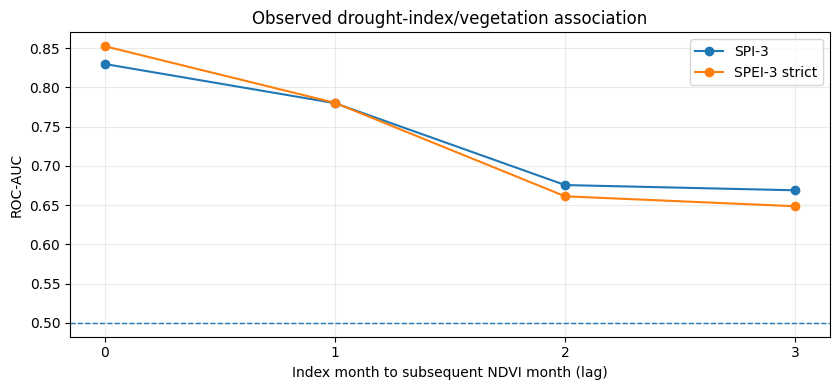

In [10]:
lag=pd.read_csv(ROOT/'outputs/impact_validation/stage3_index_vegetation_metrics.csv')
lag=lag[(lag.period=='case_2020_2022') & (lag.cohort=='paired_SPI_SPEI')]
fig,ax=plt.subplots(figsize=(8.5,4))
for label in ['SPI-3','SPEI-3 strict']:
    d=lag.loc[lag['index']==label].sort_values('lead_months')
    ax.plot(d.lead_months,d.roc_auc_vegetation_stress,'o-',label=label)
ax.axhline(.5,ls='--',linewidth=1)
ax.set(xticks=[0,1,2,3],xlabel='Index month to subsequent NDVI month (lag)',ylabel='ROC-AUC',title='Observed drought-index/vegetation association')
ax.legend();ax.grid(alpha=.25);fig.tight_layout();plt.show()

## 6. Northern Tanzania case study: 2020–2022

The study examines **Longido** and **Monduli** (Arusha Region) and **Simanjiro** (Manyara Region). The original September 2021 TMA Vuli outlook warned of dry spells and pasture/water stress; the February 2022 Masika outlook broadly anticipated normal-to-above-normal rainfall in northeastern Tanzania, while later observed rainfalls were below their reference averages.

The TMA bulletins are **regional seasonal forecasts**; our case-study rainfall is **district-level gridded observation**. They are not equivalent spatial or probability forecasts. We therefore describe their qualitative alignment rather than assigning a fabricated numerical TMA forecasting skill.

,district,season,rainfall_mm,rainfall_percent_of_reference,observed_empirical_tercile,end_spi3,end_spei3,end_ndvi_z
1,Longido,Masika 2022 (MAM),219.00,67.37,below-normal,-0.94,NaN,-0.91
0,Longido,Vuli 2021 (OND),124.99,61.59,below-normal,-0.73,-0.96,-0.76
3,Monduli,Masika 2022 (MAM),240.41,74.03,below-normal,-0.92,-1.32,-1.56
2,Monduli,Vuli 2021 (OND),97.49,47.88,below-normal,-0.91,-1.04,-1.18
5,Simanjiro,Masika 2022 (MAM),213.25,64.05,below-normal,-1.38,-1.93,-0.39
4,Simanjiro,Vuli 2021 (OND),92.12,51.70,below-normal,-0.81,-1.05,-0.79


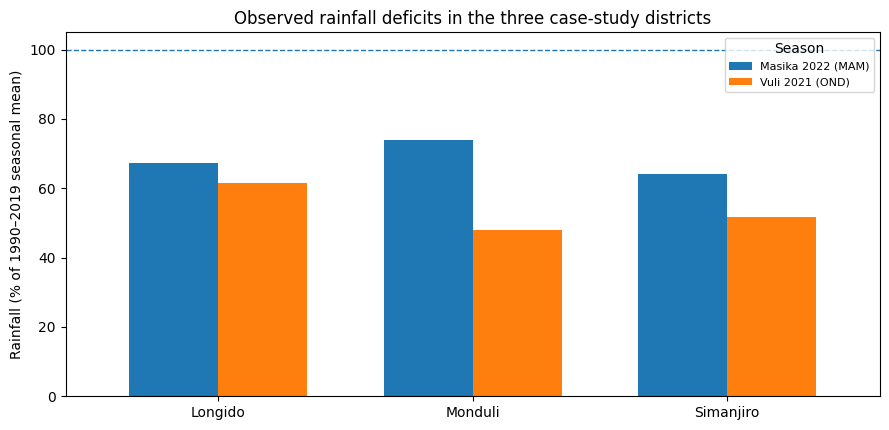

In [11]:
case=pd.read_csv(ROOT/'outputs/case_study/stage4_district_season_comparison.csv')
cols=['district','season','rainfall_mm','rainfall_percent_of_reference','observed_empirical_tercile','end_spi3','end_spei3','end_ndvi_z']
display(case[cols].round(2).sort_values(['district','season']))
fig,ax=plt.subplots(figsize=(9,4.4))
wide=case.pivot(index='district',columns='season',values='rainfall_percent_of_reference')
wide.plot.bar(ax=ax,width=.7)
ax.axhline(100,ls='--',linewidth=1)
ax.set(xlabel='',ylabel='Rainfall (% of 1990–2019 seasonal mean)',title='Observed rainfall deficits in the three case-study districts')
ax.tick_params(axis='x',rotation=0);ax.legend(title='Season',fontsize=8)
fig.tight_layout();plt.show()

In [12]:
evidence=pd.read_csv(ROOT/'data/standardized/tma_evidence.csv')
display(evidence[['source_date','source_id','evidence_summary','limitation','url']])

,source_date,source_id,evidence_summary,limitation,url
0,2021-09-02,TMA_VULI_2021,TMA bulletin (original) held regional below-to...,"Regional outlook, not district probability",https://www.meteo.go.tz/uploads/weathers/forec...
1,2022-02-17,TMA_MASIKA_2022,TMA bulletin (original) anticipated normal-to-...,Regional outlook; explicit advice to monitor u...,https://www.meteo.go.tz/uploads/weathers/forec...
2,2022-04-13,TMA_MASIKA_UPDATE,TMA update recognized March dry spells and rev...,Update does not constitute an advance forecast...,https://www.meteo.go.tz/uploads/weathers/forec...
3,post-event publication 2022,TMA_CLIMATE_2021,TMA confirmed Simanjiro cattle/livestock droug...,National total NOT district count,https://www.meteo.go.tz/uploads/publications/s...
4,post-event publication,TMA_CLIMATE_2022,TMA reported 2022 MAM second driest nationally...,Station/national context; can differ from CHIR...,https://www.meteo.go.tz/uploads/documents/sw-1...
5,2022-01-22,ANADOLU_SIMANJIRO,Deputy chair Simanjiro district council report...,"Reported figure, not independently audited cen...",https://www.aa.com.tr/en/africa/fighting-droug...


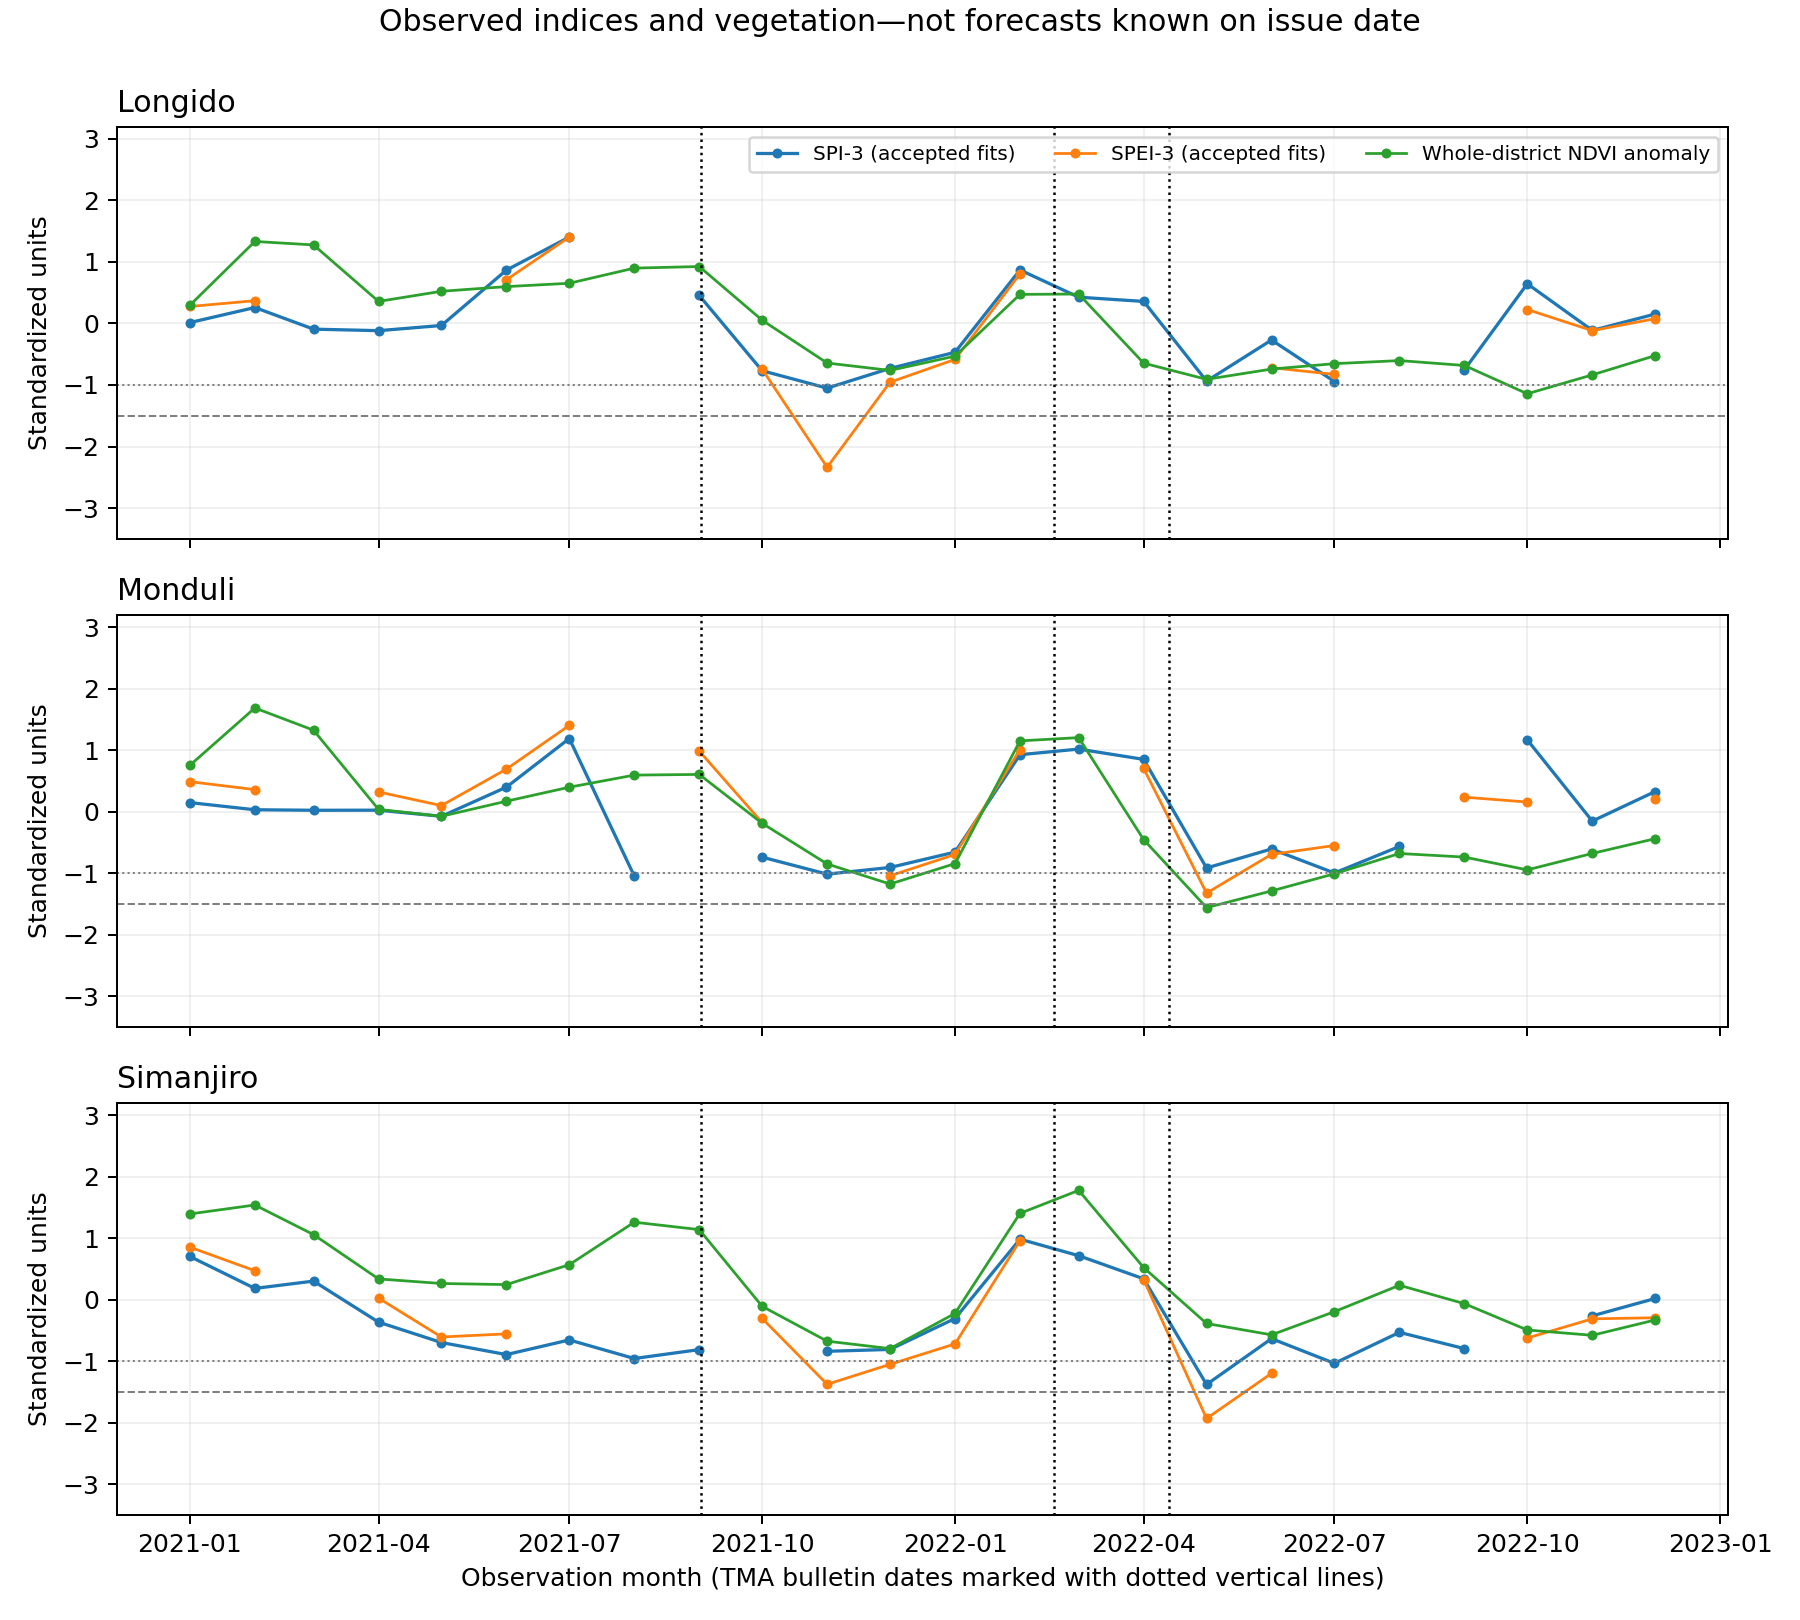

In [13]:
# Monthly case-study timeline using saved, verified drought indices and satellite vegetation anomalies.
from IPython.display import Image
display(Image(filename=str(ROOT/'outputs/case_study/stage4_indices_vegetation_monthly_timeline.png'),width=810))

## 7. Mathematical forecasting: targets, models and temporal design

Unlike SPI-3 and SPEI-3 (monitoring scores), a **forecast model** uses observations known at the issue date to estimate a future event probability.

The two retrospectively evaluated targets are:

$$Y^{\mathrm{severe}}_{d,t+h}=\mathbf{1}\{SPI_{3,d,t+h}\leq-1.5\},\qquad
Y^{\mathrm{vegetation}}_{d,t+h}=\mathbf{1}\{Z_{NDVI,d,t+h}\leq-1\}, \quad h\in\{1,2,3\}.$$

**Four benchmark/candidate approaches** were evaluated for both targets and all leads:

- **Seasonal climatology:** empirical district/calendar-month event frequency estimated only on training years.
- **SPI persistence:** empirical probability conditional on the latest known SPI category, estimated on training years.
- **Logistic regression:** $p=1/(1+\exp[-(\beta_0+\boldsymbol\beta^T\mathbf{x})])$, with regularization, imputation, standardized numerical features and district effects.
- **Histogram gradient boosting:** an ensemble of additive decision trees modelling nonlinear interactions and thresholds.

An exploratory **50:50 average of logistic and boosting probabilities**, plus optional post-calibration, was investigated in Stage 6. It should not be represented as a proven operational winner.

**Temporal split (by target year):**

| Years | Purpose |
|---|---|
| 1985–2014 | Train the original forecasting models |
| 2015–2017 | Subsequent probability calibration |
| 2018–2019 | Subsequent model and alert-threshold selection |
| 2020–2022 | Retrospective drought case evaluation |
| 2023–2025 | Additional retrospective evaluation |

The original Stage 5 threshold selection used the combined **2015–2019 validation period**, whereas Stage 6 split it into calibration (2015–2017) and selection (2018–2019). Neither procedure fits the trained model using a 2020–2025 event label. However, the **fixed 1990–2019 index reference** and reanalysis observations are not strictly issue-time vintage products. This is a limitation of the retrospective experiment.

In [14]:
metrics=pd.read_csv(ROOT/'outputs/forecasting/stage5_performance_metrics.csv')
assert len(metrics)==72
sel=metrics[(metrics.period=='case_2020_2022') & (metrics.lead_months==1)][['target','model','n','events','roc_auc','brier','true_positive','false_positive','recall','precision']]
display(sel.sort_values(['target','brier']).round(4))

,target,model,n,events,roc_auc,brier,true_positive,false_positive,recall,precision
5,severe_spi3,spi_persistence,4671,92,0.6061,0.0205,47,1512,0.5109,0.0301
7,severe_spi3,gradient_boosting,4671,92,0.7782,0.0206,30,440,0.3261,0.0638
6,severe_spi3,logistic,4671,92,0.7611,0.0209,40,597,0.4348,0.0628
4,severe_spi3,seasonal_climatology,4671,92,0.5413,0.0212,91,4259,0.9891,0.0209
42,vegetation_stress,logistic,2538,262,0.8287,0.0742,198,561,0.7557,0.2609
43,vegetation_stress,gradient_boosting,2538,262,0.8170,0.0756,196,583,0.7481,0.2516
41,vegetation_stress,spi_persistence,2538,262,0.7165,0.0873,207,1025,0.7901,0.1680
40,vegetation_stress,seasonal_climatology,2538,262,0.5187,0.0951,262,2276,1.0000,0.1032


In [15]:
# Independently recalculate probabilities' Brier score and AUC from saved individual forecasts.
hind=pd.read_csv(ROOT/'outputs/forecasting/stage5_2020_2025_hindcast_predictions.csv')
subset=hind[(hind.target=='vegetation_stress') & (hind.lead_months==1) & (hind.period=='case_2020_2022')]
y=subset.observed_event.astype(int).to_numpy()
p=subset.logistic_prob.to_numpy(float)
recomputed_brier=brier_score_loss(y,p)
recomputed_auc=roc_auc_score(y,p)
saved=metrics[(metrics.target=='vegetation_stress')&(metrics.lead_months==1)&(metrics.period=='case_2020_2022')&(metrics.model=='logistic')].iloc[0]
print(f'Independent one-month vegetation model evaluation: N={len(y)}; Brier={recomputed_brier:.5f}; AUC={recomputed_auc:.5f}')
assert abs(recomputed_brier-saved.brier)<1e-5
assert abs(recomputed_auc-saved.roc_auc)<1e-5

Independent one-month vegetation model evaluation: N=2538; Brier=0.07423; AUC=0.82871


In [16]:
# Reconstruct a sample probability directly from the saved executable Logistic Regression estimator.
sys.path.insert(0,str(ROOT/'src'/'engine'))
from TMA_P06_Stage5_Models import data_and_features, prep_lead, inputs
features_df, _, _ = data_and_features(ROOT)
q1 = prep_lead(features_df,1,'severe_spi3')
example_rows=q1[(q1.district.isin(['Longido','Monduli','Simanjiro'])) & (q1.month.dt.year==2021)].head(5)
assert len(example_rows)
model=joblib.load(ROOT/'models/severe_spi3_lead1_logistic.joblib')
feature_columns=inputs('severe_spi3')+['district_id']
pred=model.predict_proba(example_rows[feature_columns])[:,1]
display(example_rows[['district','month','target_month','event']].assign(reconstructed_probability=np.round(pred,4)))
print('These are retrospective probabilities: the actual future labels shown here are for evaluation only.')

,district,month,target_month,event,reconstructed_probability
4260,Monduli,2021-01-01,2021-02-01,0,0.0753
4261,Monduli,2021-02-01,2021-03-01,0,0.1145
4262,Monduli,2021-03-01,2021-04-01,0,0.0376
4263,Monduli,2021-04-01,2021-05-01,0,0.0557
4264,Monduli,2021-05-01,2021-06-01,0,0.0236


These are retrospective probabilities: the actual future labels shown here are for evaluation only.


## 8. Forecast evaluation: detection, missed events and false alarms

For observed label $Y_i\in\{0,1\}$ and predicted probability $p_i$:

- **Brier score:** $\frac1N\sum_i(p_i-Y_i)^2$; lower is better.
- **ROC-AUC:** probability of ranking a randomly selected event above a non-event; higher is better.
- **Recall:** $TP/(TP+FN)$, the fraction of actual events detected.
- **Precision:** $TP/(TP+FP)$, the share of issued alerts that correspond to events.
- **False-alarm rate:** $FP/(FP+TN)$ among observed non-event months.

A high AUC does **not** necessarily mean usable drought warnings; rare events can produce many false alarms. Compare each forecasting lead independently and retain the seasonal-climatology and SPI-persistence baselines.

In [17]:
case_metrics=metrics[metrics.period=='case_2020_2022'].copy()
fig,axes=plt.subplots(1,2,figsize=(11.6,4.3),sharex=True)
for ax,target,title in zip(axes,['severe_spi3','vegetation_stress'],['Severe SPI-3 event','NDVI vegetation stress']):
    for model_name in ['seasonal_climatology','spi_persistence','logistic','gradient_boosting']:
        z=case_metrics[(case_metrics.target==target)&(case_metrics.model==model_name)].sort_values('lead_months')
        ax.plot(z.lead_months,z.roc_auc,'o-',label=model_name.replace('_',' '))
    ax.set(title=title,xlabel='Forecast lead (months)',ylabel='ROC-AUC',xticks=[1,2,3])
    ax.grid(alpha=.25)
axes[1].legend(fontsize=8,loc='best');fig.suptitle('2020–2022 retrospective model discrimination')
fig.tight_layout();plt.show()

/tmp/ipykernel_13413/3417548300.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout();plt.show()


In [18]:
opt=pd.read_csv(ROOT/'outputs/optimization/stage6_performance_metrics.csv')
choose=pd.read_csv(ROOT/'outputs/optimization/stage6_model_selection_and_warning_rules.csv')
case_opt=opt[(opt.period=='case_2020_2022')&(opt.lead_months==1)]
display(case_opt[['target','model','selected_candidate','n','events','roc_auc','brier','true_positive','false_positive','recall','precision']].round(4))
display(choose[['target','lead_months','selected_model','threshold']].sort_values(['target','lead_months']))

,target,model,selected_candidate,n,events,roc_auc,brier,true_positive,false_positive,recall,precision
10,severe_spi3,chosen_stage6,spi_persistence,4671,92,0.6061,0.0205,2,25,0.0217,0.0741
11,severe_spi3,stage5_raw_logistic,spi_persistence,4671,92,0.7611,0.0209,10,106,0.1087,0.0862
12,severe_spi3,stage5_raw_boosting,spi_persistence,4671,92,0.7782,0.0206,7,99,0.0761,0.0660
13,severe_spi3,spi_persistence,spi_persistence,4671,92,0.6061,0.0205,2,25,0.0217,0.0741
14,severe_spi3,seasonal_climatology,spi_persistence,4671,92,0.5413,0.0212,0,0,0.0000,NaN
70,vegetation_stress,chosen_stage6,spi_persistence,2538,262,0.7165,0.0873,44,133,0.1679,0.2486
71,vegetation_stress,stage5_raw_logistic,spi_persistence,2538,262,0.8287,0.0742,145,233,0.5534,0.3836
72,vegetation_stress,stage5_raw_boosting,spi_persistence,2538,262,0.8170,0.0756,121,181,0.4618,0.4007
73,vegetation_stress,spi_persistence,spi_persistence,2538,262,0.7165,0.0873,44,133,0.1679,0.2486
74,vegetation_stress,seasonal_climatology,spi_persistence,2538,262,0.5187,0.0951,7,38,0.0267,0.1556


,target,lead_months,selected_model,threshold
0,severe_spi3,1,spi_persistence,0.190000
1,severe_spi3,2,spi_persistence,1.000000
2,severe_spi3,3,raw_blend,0.080488
3,vegetation_stress,1,spi_persistence,0.217039
4,vegetation_stress,2,spi_persistence,0.193579
5,vegetation_stress,3,spi_persistence,0.184892


## 9. Scientific conclusions and next steps

**Historical reconstruction.** The rainfall record supports district-month SPI-3 reconstruction and maps; strict SPEI-3 remains incomplete because many evaporation and fitted-distribution cases fail QC.

**Index–impact association.** On the **1,317 matching district-months in 69 districts** during 2020–2022, strict SPEI-3 has higher contemporaneous NDVI association and AUC than SPI-3. This is conditional on a restricted quality-accepted cohort, and it does not establish causality or national superiority.

**Case study.** The 2021 Vuli outlook gave meaningful qualitative drought/pasture warnings; the initial Masika 2022 forecast contrasts with subsequently observed regional rainfall deficits. A direct numerical score of TMA's historical forecast versus our models is not justified without archived comparable forecast probabilities and spatial definitions.

**Forecasting.** One-month vegetation-stress models show stronger retrospective discrimination than severe-drought models, but numerical improvements from a 50:50 combination are exploratory. Severe-drought warnings at two and three months do not yet show operationally reliable skill.

**Required further research:** acquire genuine issue-time seasonal forecast/hindcast predictors (e.g. C3S), improve local vegetation/pasture coverage, seek dated district crop/livestock records, refine calibration with genuinely independent data, and test on an untouched future period. The web dashboard in `dashboard/` presents **saved historical predictions** rather than issuing live operational warnings.

In [19]:
# Final integrity checks and reproducibility references.
assert len(hind)==43_068
assert len(case)==6
assert len(metrics)==72 and len(opt)==120
assert (ROOT/'run_project.py').exists()
print('NOTEBOOK VERIFICATION PASSED')
print('Rows: climate =',len(master),'; matched vegetation case =',len(paired),'; hindcasts =',len(hind))
print('Full re-execution: python run_project.py --mode all')
print('Dashboard: dashboard/TMA_P06_STAGE7_OFFLINE_DROUGHT_DASHBOARD.html')

NOTEBOOK VERIFICATION PASSED
Rows: climate = 81000 ; matched vegetation case = 1317 ; hindcasts = 43068
Full re-execution: python run_project.py --mode all
Dashboard: dashboard/TMA_P06_STAGE7_OFFLINE_DROUGHT_DASHBOARD.html


### Source files and reproducibility

- Input archive: `data/raw/TMA(1).zip` (original supplied files, preserved).
- Standardized data: `data/standardized/` and `data/processed/`.
- Model methods: `src/engine/historical.py`, `impact_validation.py`, `case_study.py`, `TMA_P06_Stage5_Models.py`, `optimization.py`.
- Saved statistical outputs: `outputs/`.
- Trained estimators: `models/`; dashboard: `dashboard/`.
- Source and variable definitions: `documentation/DATA_DICTIONARY.csv`, `documentation/DATA_LINEAGE.csv`.
- Primary TMA historical documents and source URLs: `data/standardized/tma_evidence.csv`.

**Computational reproducibility is not external scientific validation.** The notebook preserves observed missingness and does not create synthetic impact data, assume crop losses, or generate live weather forecasts.